In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0
from functools import lru_cache


In [2]:


def construir_espacio_de_Fock(L, N):

    if N == 1:
        return [(L,)]

    espacio = []

    for n0 in range(L + 1):
        estado_restantes = construir_espacio_de_Fock(L - n0, N - 1)
        for estado in estado_restantes:
            espacio.append((n0,) + estado)

    return espacio



L = 6
N = 6
espacio_de_Fock = np.array(construir_espacio_de_Fock(L, N), dtype=int)

print("Espacio de Fock:")
print(espacio_de_Fock[:10])  # Mostrar solo los primeros 10 estados para no saturar la salida




Espacio de Fock:
[[0 0 0 0 0 6]
 [0 0 0 0 1 5]
 [0 0 0 0 2 4]
 [0 0 0 0 3 3]
 [0 0 0 0 4 2]
 [0 0 0 0 5 1]
 [0 0 0 0 6 0]
 [0 0 0 1 0 5]
 [0 0 0 1 1 4]
 [0 0 0 1 2 3]]


In [3]:
def E_U(estado):
    return (1/2)*np.sum(estado * (estado - 1))

In [4]:
indice_estado = {tuple(estado): i for i, estado in enumerate(espacio_de_Fock)}

In [5]:
numero_sitios = 6
numeros_de_onda = 2 * np.pi * np.arange(numero_sitios) / numero_sitios


def M(kappa, k_l, k_m, k_n):
    argumento = 2 * kappa * (
        np.cos(k_l)
        + np.cos(k_m)
        - np.cos(k_l + k_m - k_n)
        - np.cos(k_n)
    )
    return j0(argumento)


@lru_cache(maxsize=None)
def Q(kappa, w, x, y, z):
    Q = 0.0 + 0.0j

    for l in range(numero_sitios):
        k_l = numeros_de_onda[l]

        for m in range(numero_sitios):
            k_m = numeros_de_onda[m]

            for n in range(numero_sitios):
                k_n = numeros_de_onda[n]
                fase = (
                    k_l * (x - y)
                    + k_m * (x - z)
                    - k_n * (x - w)
                )
                Q += M(kappa, k_l, k_m, k_n) * np.exp(1j * fase)
    Q *= 1/(2*numero_sitios**3)

    return Q

In [ ]:

@lru_cache(maxsize=None)
def construir_H_eff(kappa):

    dimension = len(espacio_de_Fock)

    H_eff = np.zeros(
        (dimension, dimension),
        dtype=complex
    )

    for indice_inicial, estado in enumerate(espacio_de_Fock):

        # Identificamos los sitios que contienen al menos un bosón
        sitios_ocupados = np.flatnonzero(estado)

        # Operadores de destrucción: a_z y a_y
        for z in sitios_ocupados:
            for y in sitios_ocupados:

                # Si y == z, necesitamos al menos dos bosones
                if y == z and estado[z] < 2:
                    continue

                # Operadores de creación: a_x^dagger y a_w^dagger
                for x in range(numero_sitios):
                    for w in range(numero_sitios):

                        resultado = aplicar_operadores(
                            estado, w, x, y, z
                        )

                        if resultado is None:
                            continue

                        nuevo_estado, A = resultado

                        indice_nuevo = indice_estado[
                            tuple(nuevo_estado)
                        ]

                        H_eff[indice_nuevo, indice_inicial] += (
                            Q(kappa, w, x, y, z) * A
                        )

    return H_eff




def aplicar_operadores(estado, w, x, y, z):

    # Primera destrucción: a_z
    if estado[z] == 0:
        return None

    nuevo_estado = estado.copy()
    A = np.sqrt(nuevo_estado[z])
    nuevo_estado[z] -= 1

    # Segunda destrucción: a_y
    if nuevo_estado[y] == 0:
        return None

    A *= np.sqrt(nuevo_estado[y])
    nuevo_estado[y] -= 1

    # Primera creación: a_x^dagger
    A *= np.sqrt(nuevo_estado[x] + 1)
    nuevo_estado[x] += 1

    # Segunda creación: a_w^dagger
    A *= np.sqrt(nuevo_estado[w] + 1)
    nuevo_estado[w] += 1

    return nuevo_estado, A

In [7]:
energias_U = np.array([E_U(estado) for estado in espacio_de_Fock])
H_U = np.diag(energias_U)


def evaluar_energias(kappa):
    H_eff = construir_H_eff(kappa)

    if not np.allclose(H_eff, H_eff.conj().T, rtol=1e-10, atol=1e-10):
        error = np.max(np.abs(H_eff - H_eff.conj().T))
        raise ValueError(
            f"El Hamiltoniano no es hermítico; discrepancia máxima: {error:.3e}"
        )

    return np.linalg.eigvalsh(H_eff)

In [ ]:
numero_puntos_kappa = 21
valores_kappa = np.linspace(0, 1, numero_puntos_kappa)
espectro = np.array(
    [evaluar_energias(float(kappa)) for kappa in valores_kappa]
)

fig, ax = plt.subplots(figsize=(9, 6))

for nivel in espectro.T:
    ax.plot(valores_kappa, nivel, color="tab:blue", linewidth=0.6, alpha=0.45)

ax.set_xlabel(r"$\kappa$")
ax.set_ylabel("Energía")
ax.set_title(r"Espectro de $H_{\mathrm{eff}}(\kappa)$")
ax.set_xlim(0, 1)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [ ]:
def obtener_estado_fundamental(kappa):
    H_eff = construir_H_eff(float(kappa))

    if not np.allclose(H_eff, H_eff.conj().T, rtol=1e-10, atol=1e-10):
        error = np.max(np.abs(H_eff - H_eff.conj().T))
        raise ValueError(
            f"El Hamiltoniano no es hermítico; discrepancia máxima: {error:.3e}"
        )

    energias, autovectores = np.linalg.eigh(H_eff)
    E_0 = energias[0]
    estado_fundamental = autovectores[:, 0]

    return E_0, estado_fundamental


resultados_fundamentales = [
    obtener_estado_fundamental(kappa) for kappa in valores_kappa
]

energias_fundamentales = np.array(
    [resultado[0] for resultado in resultados_fundamentales]
)
estados_fundamentales = np.array(
    [resultado[1] for resultado in resultados_fundamentales]
)

In [ ]:
def P(j, l, estado_fundamental):
    # Calcula <psi_0|a_j^dagger a_l|psi_0> en la base de Fock.
    c = np.asarray(estado_fundamental)
    if c.shape != (len(espacio_de_Fock),):
        raise ValueError("Debe haber una amplitud por estado de Fock.")
    if not (0 <= j < espacio_de_Fock.shape[1] and 0 <= l < espacio_de_Fock.shape[1]):
        raise ValueError("Los índices j y l deben estar entre 0 y 5.")

    suma = 0.0 + 0.0j
    for t, estado_t in enumerate(espacio_de_Fock):
        for s, estado_s in enumerate(espacio_de_Fock):
            if estado_s[l] == 0:
                continue

            nuevo_estado = estado_s.copy()
            factor = np.sqrt(nuevo_estado[l])
            nuevo_estado[l] -= 1
            factor *= np.sqrt(nuevo_estado[j] + 1)
            nuevo_estado[j] += 1

            if np.array_equal(estado_t, nuevo_estado):
                suma += c[s] * np.conjugate(c[t]) * factor

    return suma

In [ ]:
# Reejecuta esta celda para vaciar la caché si cambias P o el Hamiltoniano.
correlaciones_por_kappa = {}


def calcular_correlaciones(kappa, progreso=None):
    kappa = float(kappa)
    L = espacio_de_Fock.shape[1]
    if kappa in correlaciones_por_kappa:
        if progreso is not None:
            progreso(L * L, "Correlaciones recuperadas de memoria")
        return correlaciones_por_kappa[kappa]

    if progreso is not None:
        progreso(0, "Calculando estado fundamental")
    _, psi_0 = obtener_estado_fundamental(kappa)
    matriz = np.zeros((L, L), dtype=complex)

    for j in range(L):
        for l in range(L):
            if progreso is not None:
                progreso(j * L + l, f"Calculando P({j}, {l})")
            matriz[j, l] = P(j, l, psi_0)
            if progreso is not None:
                progreso(j * L + l + 1, f"Calculado P({j}, {l})")

    # Solo se guardan matrices completas.
    correlaciones_por_kappa[kappa] = matriz
    return matriz


def rho_desde_correlaciones(k, matriz):
    # Sumatorio sin normalización por L; k es el número de onda.
    L = matriz.shape[0]
    posiciones = np.arange(L)
    diferencias = posiciones[:, None] - posiciones[None, :]
    suma = np.sum(np.exp(1j * k * diferencias) * matriz)
    return np.real_if_close(suma)


def rho(k, kappa):
    return rho_desde_correlaciones(k, calcular_correlaciones(kappa))

In [ ]:
import json
import os
from datetime import datetime
from pathlib import Path
from time import perf_counter

ks = numeros_de_onda
kappas = np.linspace(0, 1, 21)
L = espacio_de_Fock.shape[1]

# Un archivo de estado de la última ejecución, consultable sin acceder al kernel.
archivo_progreso = Path(
    r"C:\Users\Propietario\Downloads\apuntes tfg\progreso_rho.json"
)
inicio = perf_counter()
inicio_fecha = datetime.now().astimezone().isoformat()
total = len(kappas) * L * L
completadas = 0
indice_kappa = 0
kappa_actual = None
estado_ejecucion = "en_curso"

R = np.full((len(kappas), len(ks)), np.nan, dtype=complex)
matrices_correlaciones = np.full(
    (len(kappas), L, L), np.nan, dtype=complex
)


def registrar_progreso(fase):
    transcurrido = perf_counter() - inicio
    restante = (
        transcurrido * (total - completadas) / completadas
        if completadas > 0 else None
    )
    datos = {
        "estado": estado_ejecucion,
        "pid": os.getpid(),
        "inicio": inicio_fecha,
        "actualizado": datetime.now().astimezone().isoformat(),
        "fase": fase,
        "indice_kappa": indice_kappa,
        "total_kappas": len(kappas),
        "kappa": kappa_actual,
        "correlaciones_completadas": completadas,
        "correlaciones_totales": total,
        "porcentaje": 100 * completadas / total,
        "segundos_transcurridos": transcurrido,
        "segundos_restantes_estimados": restante,
    }
    temporal = archivo_progreso.with_suffix(".tmp")
    temporal.write_text(json.dumps(datos, indent=2), encoding="utf-8")
    temporal.replace(archivo_progreso)

    estimacion = "calculando" if restante is None else f"{restante / 60:.1f} min"
    print(
        f"\rκ {indice_kappa}/{len(kappas)} | "
        f"P: {completadas}/{total} ({100 * completadas / total:.1f}%) | "
        f"transcurrido: {transcurrido / 60:.1f} min | "
        f"restante aprox.: {estimacion} | {fase}".ljust(170),
        end="", flush=True,
    )


try:
    registrar_progreso("Inicio del barrido")
    for i, kappa in enumerate(kappas):
        indice_kappa = i + 1
        kappa_actual = float(kappa)
        base = i * L * L

        def actualizar_correlaciones(locales, fase):
            global completadas
            completadas = base + locales
            registrar_progreso(fase)

        matriz = calcular_correlaciones(kappa, actualizar_correlaciones)
        matrices_correlaciones[i] = matriz
        # Los seis momentos utilizan la misma matriz: no se vuelve a llamar a P.
        for ik, k in enumerate(ks):
            R[i, ik] = rho_desde_correlaciones(k, matriz)

    R = np.real_if_close(R)
    estado_ejecucion = "completado"
    registrar_progreso("Barrido terminado")
except KeyboardInterrupt:
    estado_ejecucion = "interrumpido"
    registrar_progreso("Interrumpido por el usuario")
    raise
except Exception as error:
    estado_ejecucion = "error"
    registrar_progreso(f"{type(error).__name__}: {error}")
    raise
finally:
    print()

κ 21/21 | P: 756/756 (100.0%) | transcurrido: 14.0 min | restante aprox.: 0.0 min | Barrido terminado                                                                    


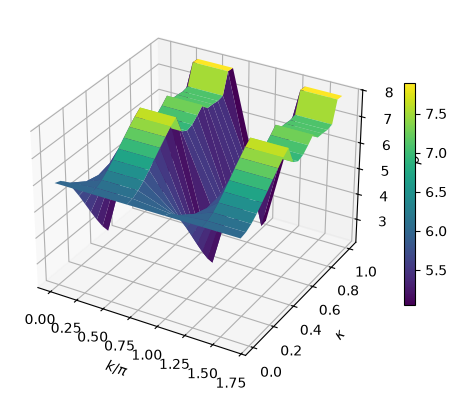

In [ ]:
K, KAPPA = np.meshgrid(ks / np.pi, kappas)

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

superficie = ax.plot_surface(
    K, KAPPA, R,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel(r"$k/\pi$")
ax.set_ylabel(r"$\kappa$")
ax.set_zlabel(r"$\rho$")
fig.colorbar(superficie, ax=ax, shrink=0.6)
plt.show()